# Step 1 — Hand-tune the supra-threshold ERP

First stage of the ERP tuning pipeline for the `duecker_ET_model`:

1. **Step 1 — hand-tune (this notebook):** manually set the evoked-drive timing and
   synaptic weights until the simulated dipole qualitatively matches the measured ERP.
   This provides the starting point for the optimiser.
2. **Step 2 — optimise (`optim_ERP_cma.py`):** refine those drive parameters with
   CMA-ES against the experimental waveform (run on the cluster via `optim_ERP_cma.sh`).
3. **Step 3 — inspect results (`optim_ERP_results.ipynb`):** load the optimiser
   checkpoint and analyse the fitted ERP.

**Target:** the S1 supra-threshold (detected) MEG ERP, `data/hnn-data/MEG_detection_data/S1_SupraT.txt`.


## Environment setup (OSCAR / MPI only)

Cluster-specific MPI/library paths. Left commented — only uncomment when running
on OSCAR.

In [1]:
# ONLY NECESSARY WHEN RUNNING ON OSCAR (uncomment)

import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"


import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

# print("Updated PATH to include MPI")
# print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



## Imports and plotting setup

In [2]:
from hnn_tuning import REPO_ROOT
pth = str(REPO_ROOT)


In [3]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys
sys.path.append(pth)

import hnn_core

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from hnn_tuning import results_dir

figpth = results_dir('network_sim', 'ERP')

# The number of cores may need modifying depending on your current machine.
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

n_procs=10
cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

--No graphics will be displayed.


## Load the experimental target ERP

Read the measured supra-threshold dipole and set the simulation length (`tstop`) to
match it. `scale_factor` and `smooth_window_len` bring the model dipole onto the same
scale/smoothness as the data for comparison below.

In [4]:
exp_dpl = read_dipole(op.join(pth, 'data', 'hnn-data', 'MEG_detection_data', 'S1_SupraT.txt'))

tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

## Hand-tuned evoked drives and simulation

Build the network, then add the canonical ERP drive sequence — an early proximal drive
(`prox1`, ~15 ms), a distal drive (`dist1`, ~60 ms), and a late proximal drive
(`prox2`, ~100 ms). The AMPA/NMDA weights, timing (`mu`/`sigma`), and synaptic delays
below are the hand-tuned values; these are what Step 2 optimises. A laminar electrode
array (`probe1`) is added for current-source inspection. `bsl_cor='duecker'` applies the
model's baseline correction.

In [70]:
for key, value in weights_nmda_p2.items():
    print(f'{key} {np.log10(value)}')

L2_inhibitory -0.06550154875643228
L2_pyramidal -4.0
L5_inhibitory -6.301029995663981
L5_pyramidal -0.42021640338318983


In [52]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_inhibitory': 0.004, 
                   'L2_pyramidal': 0.03,
                   'L5_inhibitory': 0.00, 
                   'L5_pyramidal': 6e-7}
weights_nmda_p1 = {'L2_inhibitory': 0.01, 'L2_pyramidal': 0.05,
                   'L5_inhibitory': 0.01, 'L5_pyramidal': .0}
synaptic_delays_prox = {'L2_inhibitory': 0.1, 'L2_pyramidal': .1,
                        'L5_inhibitory': 1., 'L5_pyramidal': 1.}

net.add_evoked_drive('prox1', mu=15, sigma=3.5, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal', synaptic_delays=synaptic_delays_prox)

weights_ampa_d1 = {'L2_inhibitory': 0.005, 'L2_pyramidal': 0.01, 'L5_pyramidal': 1.}
weights_nmda_d1 = {'L2_inhibitory': 0.0, 'L2_pyramidal': .01, 'L5_pyramidal': 1.}
synaptic_delays_dist = {'L2_inhibitory': 0.1, 'L2_pyramidal': 0.1,'L5_pyramidal': 0.1}

net.add_evoked_drive('dist1', mu=56, sigma=4.5, numspikes=2, weights_ampa=weights_ampa_d1,
    weights_nmda=weights_nmda_d1, location='distal', synaptic_delays=synaptic_delays_dist)

weights_ampa_p2 = {'L2_inhibitory': 0.0, 'L2_pyramidal':0.305,
                   'L5_inhibitory': 0.044, 'L5_pyramidal': 0.051}
weights_nmda_p2 = {'L2_inhibitory': 0.86, 'L2_pyramidal': 0.0001,
                   'L5_inhibitory': 5e-7, 'L5_pyramidal': 0.38}
synaptic_delays_prox = {'L2_inhibitory': 0.1, 'L2_pyramidal': .1,
                        'L5_inhibitory': 1., 'L5_pyramidal': 1.}
net.add_evoked_drive('prox2', mu=99, sigma=12, numspikes=1, weights_ampa=weights_ampa_p2,
    weights_nmda=weights_nmda_p2, location='proximal', synaptic_delays=synaptic_delays_prox)


with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=3,bsl_cor='duecker')


MPI will run 3 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-c

## Scale, smooth, and average the simulated dipole

In [53]:
dpl = [d.scale(scale_factor) for d in dpl]
dpl = [d.smooth(smooth_window_len) for d in dpl]
avg_dpl = average_dipoles(dpl)

## Compare model to data

Spike histograms + raster (top/left) alongside the simulated aggregate dipole (red)
overlaid on the experimental ERP (black), plus the L2 and L5 layer contributions.

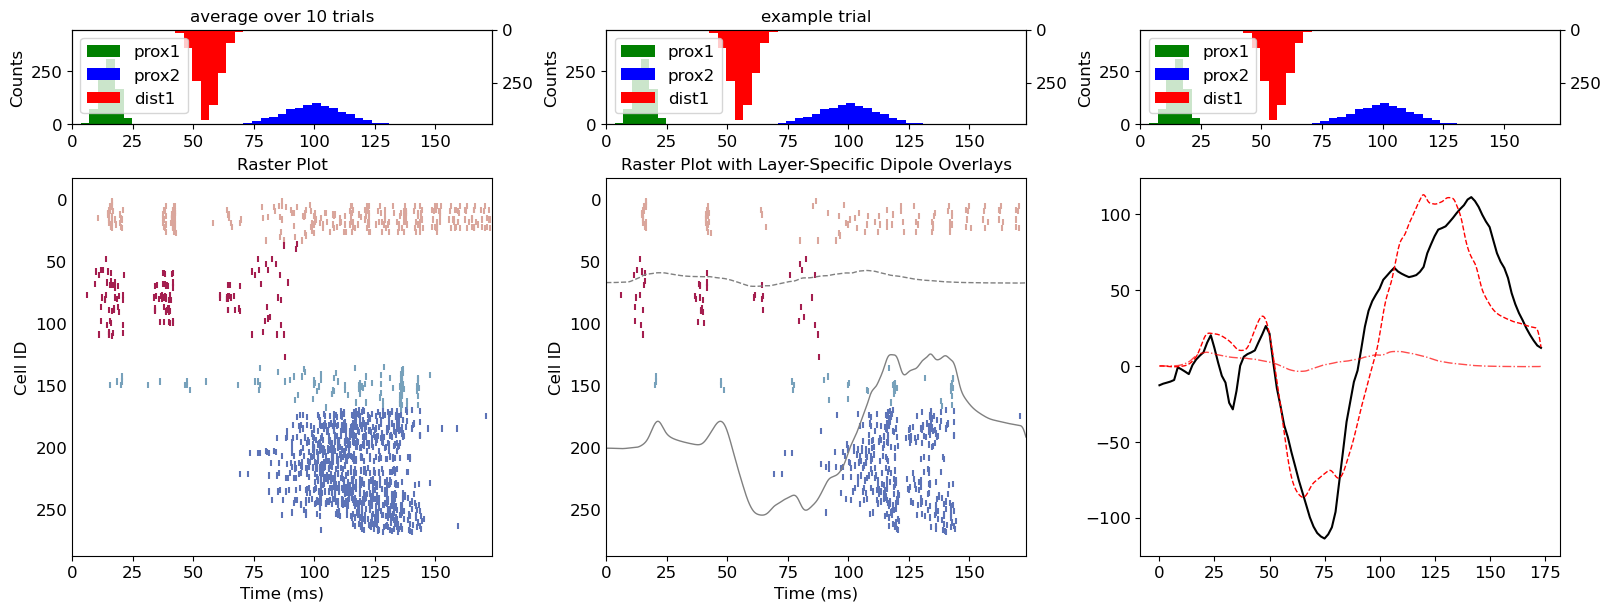

In [54]:
fig, ax = plt.subplots(2,3, figsize=(16,6), height_ratios=[0.25, 1], constrained_layout=True)

for i in range(3):
    net.cell_response.plot_spikes_hist(ax=ax[0,i], show=False, invert_spike_types='dist1')
net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False, oberlay_dipoles=True, dpl=avg_dpl, show_legend=False)
net.cell_response.plot_spikes_raster(ax=ax[1,1], trial_idx=0, show=False, overlay_dipoles=True, dpl=dpl[0], show_legend=False)

ax[0,0].set_title('average over 10 trials')
ax[0,1].set_title('example trial')


ax[1,2].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,2].plot(avg_dpl.times, avg_dpl.data['L2'], linewidth=1, color='r', alpha=0.7, linestyle='-.', label='L2')
ax[1,2].plot(avg_dpl.times, avg_dpl.data['L5'], linewidth=1, color='r', label='L5', linestyle='--')


In [8]:
net.connectivity

[L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.0002; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L5_pyramidal -> L5_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.00065; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L5_pyramidal -> L5_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.00065; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,
 L2_inhibitory -> L2_pyramidal
 cell counts: 35 srcs, 100 targets
 connection probability: 1.0 
 loc: 'soma'; receptor: 'gabaa'
 weight: 0.1; delay: 1.0; lamtha: 6.125threshold: 0.0gain: 1.0
  ,